In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pandas as pd
from sklearn import metrics
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"

In [2]:
df = pd.read_csv("../results/Cleaned_datasets/labels.csv")
images = []
class_ = {'Ring': 0, 'Arc_lens' : 1, 'Multi_lens' : 2, 'Non_lens' : 3}
for i in df['Filename']:
    file = "../results/images/" + i
    images.append(np.load(file))

y = np.array(df.Class.map(class_))
X_prescaled = np.stack(images)

In [22]:
path = "../evaluation"
os.makedirs(path, exist_ok=True)
noise = np.std(X_prescaled[:, :10, : 10])
df_noise = pd.DataFrame()
df_noise['Noise'] = [noise]
df_noise.to_csv(os.path.join(path,'noise.csv'), index=False)  
scaled = X_prescaled / noise
stretched = np.arcsinh(scaled)
m = stretched.mean(axis=(1, 2), keepdims=True)
s = stretched.std(axis=(1, 2), keepdims=True)
normed = (stretched - m) / s
X = normed

In [4]:
def split_data(X, y, frac_train=0.6, frac_val=0.2, seed=343):
    """Shuffle the examples, then split them into training, validation and test sets."""
    rng = np.random.default_rng(seed)
    n = len(X)
    idx = rng.permutation(n)
    n_train, n_val = int(frac_train * n), int(frac_val * n)
    train_idx, val_idx, test_idx = idx[:n_train], idx[n_train:n_train + n_val], idx[n_train + n_val:]
    return X[train_idx], y[train_idx], X[val_idx], y[val_idx], X[test_idx], y[test_idx]

X_train, y_train, X_val, y_val, X_test, y_test = split_data(X, y)

# Convert everything into PyTorch tensors, adding a channel dimension to the images (n, 1, nw, nh)
X_train_t = torch.tensor(X_train[:, None], dtype=torch.float32)    # (n, 1, 24, 24)
X_val_t = torch.tensor(X_val[:, None], dtype=torch.float32)
X_test_t = torch.tensor(X_test[:, None], dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)             # (n, 1)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print("training images:", tuple(X_train_t.shape))
print("validation images:", tuple(X_val_t.shape))
print("test images:", tuple(X_test_t.shape))
print("y:", tuple(y_train_t.shape))
print(np.bincount(y_train))
print(np.bincount(y_val))
print(np.bincount(y_test))

training images: (1200, 1, 100, 100)
validation images: (400, 1, 100, 100)
test images: (400, 1, 100, 100)
y: (1200,)
[272 296 315 317]
[107 101  97  95]
[121 103  88  88]


In [5]:
def accuracy(model, X_t, y_t):
    """Fraction of images classified correctly (threshold 0.5)."""
    with torch.no_grad():
        y_pred = (model(X_t).numpy().argmax(axis = 1))
    return np.mean(y_pred == y_t.numpy())

def train_model(model, optimiser, loss_fn, n_epochs, batch_size=32):
    """Mini-batch training. Uses the global tensors X_train_t, y_train_t, X_val_t, y_val_t.
    Returns lists of the training cost, validation cost, training accuracy and validation accuracy after each epoch."""
    J_train, J_val, acc_train, acc_val = [], [], [], []
    n = len(X_train_t)
    for epoch in range(n_epochs):
        perm = torch.randperm(n)                      # a new random order of the training images each epoch
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]      # the indices of the images in this mini-batch
            X_batch, y_batch = X_train_t[idx], y_train_t[idx]
            k = torch.randint(0,4, (1,)).item()
            X_batch = (torch.rot90(X_batch, k, dims=(2, 3)))
            flip = torch.randint(0,2, (1,)).item()
            if flip == 1:
                X_batch = torch.flip(X_batch, dims=(3,))
            y_hat = model(X_batch)      # TODO: forward pass on the mini-batch
            J = loss_fn(y_hat, y_batch)          # TODO: cost on the mini-batch
            optimiser.zero_grad()# TODO: clear the old gradients
            J.backward()# TODO: do backprop from J
            optimiser.step()# TODO: update the weights and biases

        with torch.no_grad():                         # end of epoch: measure, don't train
            J_train.append(loss_fn(model(X_train_t), y_train_t).item())
            J_val.append(loss_fn(model(X_val_t), y_val_t).item())
        acc_train.append(accuracy(model, X_train_t, y_train_t))
        acc_val.append(accuracy(model, X_val_t, y_val_t))
    return J_train, J_val, acc_train, acc_val

In [6]:
def plot_curves(J_train, J_val, acc_train, acc_val, title=""):
    path = "../evaluation"
    os.makedirs(path, exist_ok=True)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(J_train, color=BLUE, lw=2, label="training")
    axs[0].plot(J_val, color=ORANGE, lw=2, label="validation")
    axs[0].set_xlabel("epoch"); axs[0].set_ylabel("cost $J$"); axs[0].set_ylim(bottom=0); axs[0].legend()
    axs[1].plot(100 * np.array(acc_train), color=BLUE, lw=2, label="training")
    axs[1].plot(100 * np.array(acc_val), color=ORANGE, lw=2, label="validation")
    axs[1].axhline(25, color=GREY, ls=":", lw=1); axs[1].text(len(acc_val) - 1, 47, "guessing", ha="right", va="top", color=GREY)
    axs[1].set_xlabel("epoch"); axs[1].set_ylabel("accuracy (%)"); axs[1].set_ylim(30, 102); axs[1].legend()
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(os.path.join(path,'Cost curve.png'), dpi=300)
    plt.show()

def count_parameters(model):
    """Total number of weights and biases in the model."""
    return sum(p.numel() for p in model.parameters())

filter weights, shape (8, 1, 5, 5) = (filters, input channels, height, width)
biases, shape (8,) = one per filter
input shape: (1, 1, 100, 100)   output shape: (1, 8, 96, 96)


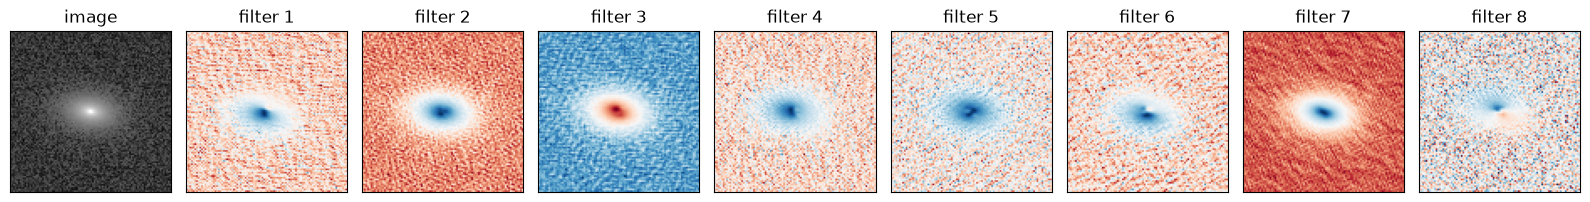

In [7]:
torch.manual_seed(0) # set the random number generator to a known state, so that the convolutional filters are the same each time
conv = nn.Conv2d(1, 8, kernel_size=5)        # 8 filters of 5 x 5, 1 input channel
print("filter weights, shape", tuple(conv.weight.shape), "= (filters, input channels, height, width)")
print("biases, shape", tuple(conv.bias.shape), "= one per filter")

one_image = X_train_t[:1]                    # shape (1, 1, 24, 24): a batch of one image
maps = conv(one_image)
print("input shape:", tuple(one_image.shape), "  output shape:", tuple(maps.shape))

fig, axs = plt.subplots(1, 9, figsize=(16, 2.4))
axs[0].imshow(one_image[0, 0].numpy(), cmap="gray"); axs[0].set_title("image")
for f in range(8):
    axs[f + 1].imshow(maps[0, f].detach().numpy(), cmap="RdBu_r"); axs[f + 1].set_title(f"filter {f + 1}")
for ax in axs: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [8]:
block1 = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1),  
    nn.ReLU(),
    nn.MaxPool2d(2))

block2 = nn.Sequential(
    nn.Conv2d(8, 16, kernel_size=3, padding=1),  
    nn.ReLU(),
    nn.MaxPool2d(2))

block3 = nn.Sequential(
    nn.Conv2d(16, 32, kernel_size=3, padding=1),  
    nn.ReLU(),
    nn.MaxPool2d(2))


one = block1(X_train_t[:1])
two = block2(one)
three = block3(two)

print(one.shape,two.shape, three.shape)

torch.Size([1, 8, 50, 50]) torch.Size([1, 16, 25, 25]) torch.Size([1, 32, 12, 12])


In [9]:
cnn = nn.Sequential(block1, block2, block3, nn.AdaptiveMaxPool2d(3), nn.Flatten(), nn.LazyLinear(32), nn.ReLU(), nn.LazyLinear(4))

In [10]:
cnn(X_train_t[:5]).shape

torch.Size([5, 4])

In [11]:
count_parameters(cnn)

15268

final training cost 0.169,  final validation cost 0.355
final training accuracy 0.927,  final validation accuracy 0.877


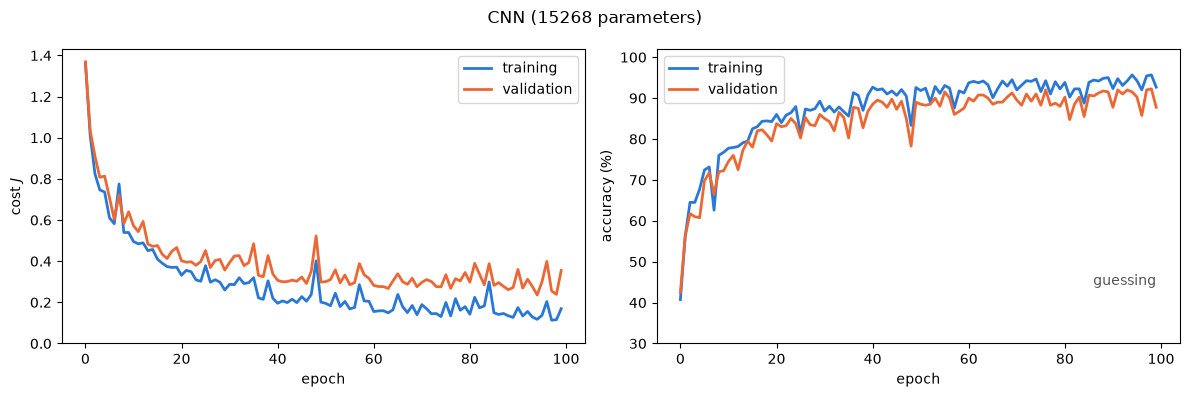

In [12]:
optimiser = torch.optim.Adam(cnn.parameters(), lr=0.002)
# TODO: fill in train_model footprint to train the model with 100 epochs
J_train, J_val, acc_train, acc_val = train_model(cnn, optimiser, nn.CrossEntropyLoss(), n_epochs = 100)

print(f"final training cost {J_train[-1]:.3f},  final validation cost {J_val[-1]:.3f}")
print(f"final training accuracy {acc_train[-1]:.3f},  final validation accuracy {acc_val[-1]:.3f}")
plot_curves(J_train, J_val, acc_train, acc_val, f"CNN ({count_parameters(cnn)} parameters)")
torch.save(cnn.state_dict(), "model_weights.pt")

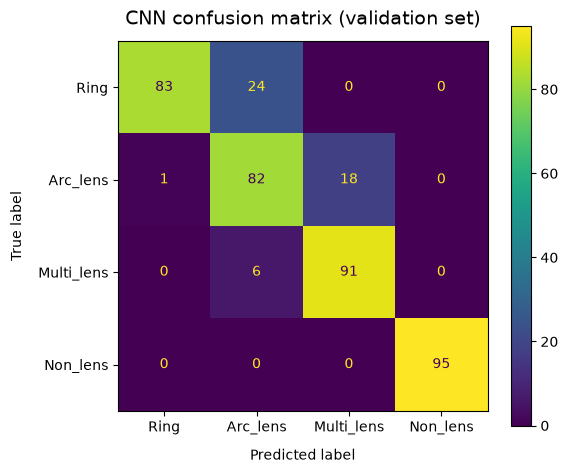

In [16]:
def matrix():
    path = "../evaluation"
    os.makedirs(path, exist_ok=True)
    
    with torch.no_grad():
        y_pred = (cnn(X_val_t).numpy().argmax(axis = 1))
    actual = y_val
    predicted = y_pred
    confusion_matrix = metrics.confusion_matrix(actual, predicted)

    df_matrix_values = pd.DataFrame()
    df_matrix_values['Actual'] = actual
    df_matrix_values['Predicted'] = predicted
    df_matrix_values.to_csv(os.path.join(path,'Matrix_values.csv'), index=False)
    
    fig, ax = plt.subplots(figsize=(6, 5)) 
    cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['Ring', 'Arc_lens', 'Multi_lens', 'Non_lens'])
    cm_display.plot(ax=ax)
    ax.set_title("CNN confusion matrix (validation set)", fontsize=14, pad=12)
    ax.set_xlabel("Predicted label", labelpad=10)
    ax.set_ylabel("True label", labelpad=10)
    plt.tight_layout()
    plt.savefig(os.path.join(path,'CNN Confusion Matrix.png'), dpi=300)
    plt.show()
    
matrix()